# E-handel – Försäljningsanalys

## 1.Introduktion

Syftet med rapporten är att analysera försäljningsdata från en e-handelsplattform.

Vi ska undersöka:
- Vilka produktkategorier som ger störst intäkter.
- Vilka städer som har högst försäljning.
- Hur försäljningen förändras över tid.
- Genomsnittligt ordervärde (AOV).
- Topp 3 produktkategorier.
- Eventuella avvikelser i försäljningen.

Avslutningsvis presenterar vi rekommendationer inför nästa kampanjperiod.

## 2. Datainläsning

Vi läser in försäljningsdata från CSV-filen och kontrollerar att informationen har lästs in korrekt.

In [11]:
import pandas as pd

df = pd.read_csv("../Data/ecommerce_sales.csv")

df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


## 3. Nyckeltal

Här sammanställer vi viktiga nyckeltal för e-handelns försäljning.

In [12]:
# Beräkna total intäkt
total_intakt = df["revenue"].sum()

# Beräkna intäkt per produktkategori
intakt_kategori = df.groupby("category")["revenue"].sum()

# Sortera kategorierna från högsta till lägsta intäkt
intakt_kategori = intakt_kategori.sort_values(ascending=False)

print("Total intäkt:", round(total_intakt, 2))
print("\nIntäkt per produktkategori:")
print(intakt_kategori)

# Beräkna totalt antal sålda enheter
totalt_antal_enheter = df["units"].sum()

# Beräkna genomsnittligt ordervärde (AOV)
# Summera först intäkten för varje unik order
order_intakter = df.groupby("order_id")["revenue"].sum()
aov = order_intakter.mean()

# Skriv ut resultaten
print("Totalt antal sålda enheter:", totalt_antal_enheter)
print("Genomsnittligt ordervärde (AOV):", round(aov, 2))

Total intäkt: 3502767.23

Intäkt per produktkategori:
category
Electronics    1364228.07
Sports          734653.42
Clothing        586744.91
Home            511070.87
Beauty          163053.97
Toys            143015.99
Name: revenue, dtype: float64
Totalt antal sålda enheter: 7463
Genomsnittligt ordervärde (AOV): 1401.11


### Egna beräkningsfunktioner

Vi har skapat två egna funktioner för att beräkna viktiga nyckeltal i försäljningsanalysen.

1. **Total försäljningsintäkt:** Funktionen summerar försäljningsintäkterna för samtliga registrerade köp.
2. **Genomsnittligt ordervärde (AOV):** Funktionen beräknar det genomsnittliga värdet per unik order.

Funktionerna gör att beräkningarna kan återanvändas och bidrar till en tydligare kodstruktur.

In [13]:
# Funktion 1: Beräkna total försäljningsintäkt
def berakna_total_intakt(df):
    return df["revenue"].sum()

# Funktion 2: Beräkna genomsnittligt ordervärde (AOV)
def berakna_aov(df):
    order_intakter = df.groupby("order_id")["revenue"].sum()
    return order_intakter.mean()

# Testa funktionerna
print("Total intäkt:", round(berakna_total_intakt(df), 2))
print("Genomsnittligt ordervärde (AOV):", round(berakna_aov(df), 2))

Total intäkt: 3502767.23
Genomsnittligt ordervärde (AOV): 1401.11


### Sammanfattning av nyckeltal

Vi har beräknat den totala försäljningsintäkten, totalt antal sålda enheter och genomsnittligt ordervärde (AOV).

Dessa nyckeltal ger en övergripande bild av e-handelns försäljning och hjälper ledningen att förstå försäljningens omfattning.

## 4. Försäljningsintäkt per produktkategori

Diagrammet visar hur försäljningsintäkterna fördelar sig mellan olika produktkategorier.

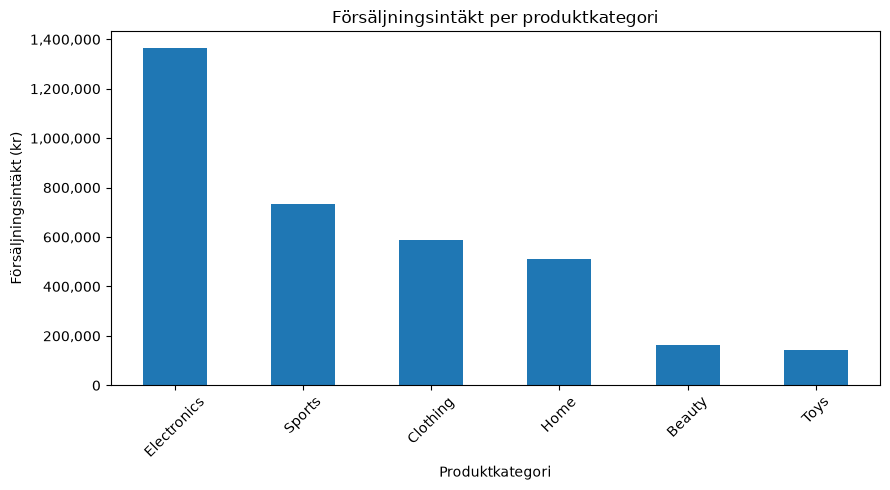

In [14]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Skapa stapeldiagram
intakt_kategori.plot(kind="bar", figsize=(9, 5))

# Rubrik och axlar
plt.title("Försäljningsintäkt per produktkategori")
plt.xlabel("Produktkategori")
plt.ylabel("Försäljningsintäkt (kr)")

# Visa hela belopp utan 1e6
plt.gca().yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}"))

# Gör diagrammet tydligare
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Analys

Electronics har högst försäljningsintäkt, följt av Sports och Clothing. Beauty och Toys har lägst intäkter under perioden.

## 5. Försäljningsintäkt per stad

Vi undersöker vilka städer som genererar störst försäljningsintäkter för att identifiera viktiga geografiska marknader inför nästa kampanjperiod.

In [15]:
# Beräkna intäkt per stad
intakt_stad = df.groupby("city")["revenue"].sum()

# Sortera från högsta till lägsta intäkt
intakt_stad = intakt_stad.sort_values(ascending=False)

# Visa resultatet
print("Försäljningsintäkt per stad:")
print(intakt_stad)

Försäljningsintäkt per stad:
city
Stockholm    1227201.94
Göteborg      859019.65
Malmö         567926.32
Uppsala       551478.42
Västerås      297140.90
Name: revenue, dtype: float64


### Analys

Stockholm genererar högst försäljningsintäkt, följt av Göteborg och Malmö. Dessa städer är viktiga marknader att undersöka vid planeringen av nästa kampanjperiod.

## 6. Försäljning över tid

Vi undersöker hur försäljningsintäkterna förändras mellan månaderna för att identifiera eventuella tidsmönster.

In [16]:
# Omvandla datum till datumformat
df["date"] = pd.to_datetime(df["date"])

# Skapa en kolumn med år och månad
df["month"] = df["date"].dt.to_period("M")

# Beräkna försäljningsintäkt per månad
intakt_manad = df.groupby("month")["revenue"].sum()

# Visa resultatet
print("Försäljningsintäkt per månad:")
print(intakt_manad)

Försäljningsintäkt per månad:
month
2024-01    664083.32
2024-02    548462.03
2024-03    487602.00
2024-04    580194.83
2024-05    632165.16
2024-06    590259.89
Freq: M, Name: revenue, dtype: float64


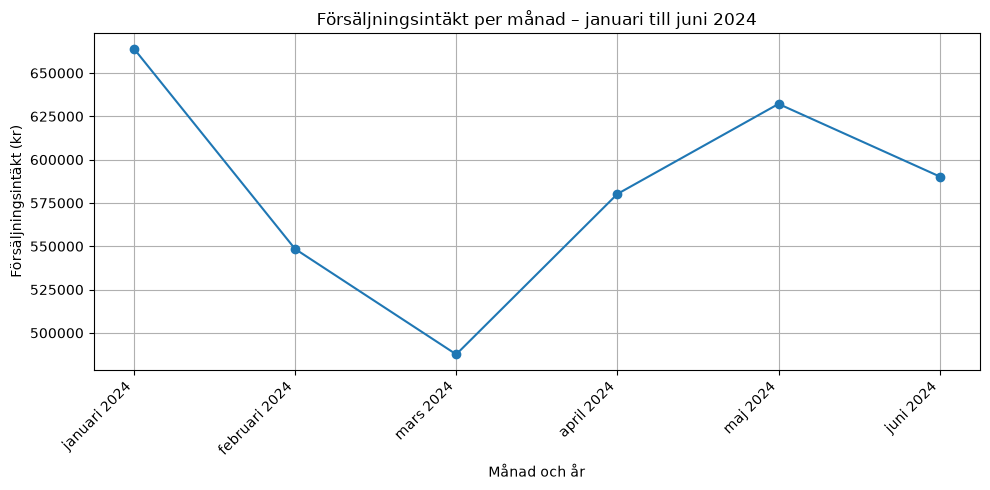

In [17]:
# Svenska månadsnamn
manader = {
    1: "januari", 2: "februari", 3: "mars",
    4: "april", 5: "maj", 6: "juni",
    7: "juli", 8: "augusti", 9: "september",
    10: "oktober", 11: "november", 12: "december"
}

# Skapa tydliga etiketter med månad och år
etiketter = [
    f"{manader[period.month]} {period.year}"
    for period in intakt_manad.index
]

# Rita linjediagrammet
plt.figure(figsize=(10, 5))
plt.plot(etiketter, intakt_manad.values, marker="o")

plt.title("Försäljningsintäkt per månad – januari till juni 2024")
plt.xlabel("Månad och år")
plt.ylabel("Försäljningsintäkt (kr)")
plt.xticks(rotation=45, ha="right")
plt.grid(True)
plt.tight_layout()
plt.show()

### Analys – Försäljning över tid

Diagrammet visar försäljningsintäkterna från januari till juni 2024.

- Januari 2024 hade högst försäljningsintäkt: 664 083,32.
- Mars 2024 hade lägst försäljningsintäkt: 487 602,00.
- Försäljningen ökade under april och maj.
- I juni minskade försäljningen något jämfört med maj.

Resultatet visar att försäljningen varierar mellan månaderna. Detta kan vara värdefull information inför planeringen av nästa kampanjperiod.

## 7. Topp 3 produktkategorier

Vi identifierar de tre produktkategorier som genererar högst försäljningsintäkter.

In [18]:
# Visa de tre kategorierna med högst intäkt
topp_3 = intakt_kategori.head(3)

print("Topp 3 produktkategorier:")
print(topp_3)

Topp 3 produktkategorier:
category
Electronics    1364228.07
Sports          734653.42
Clothing        586744.91
Name: revenue, dtype: float64


### Analys

Electronics är den mest intäktsgenererande kategorin, följt av Sports och Clothing.

Dessa tre kategorier kan vara särskilt intressanta att analysera inför nästa kampanjperiod.

## 8. Genomsnittligt ordervärde (AOV) och spridning

Vi undersöker hur mycket kunderna i genomsnitt handlar för per order och hur ordervärdena varierar.

AOV (Average Order Value) beräknas genom att dividera den totala försäljningsintäkten med antalet unika ordrar.

In [19]:
# Beräkna ordervärdet för varje unik order
order_intakter = df.groupby("order_id")["revenue"].sum()

# Beräkna AOV och spridning
aov = order_intakter.mean()
median = order_intakter.median()
minsta = order_intakter.min()
hogsta = order_intakter.max()
standardavvikelse = order_intakter.std()

# Visa resultat
print("Genomsnittligt ordervärde (AOV):", round(aov, 2))
print("Median:", round(median, 2))
print("Lägsta ordervärde:", round(minsta, 2))
print("Högsta ordervärde:", round(hogsta, 2))
print("Standardavvikelse:", round(standardavvikelse, 2))

Genomsnittligt ordervärde (AOV): 1401.11
Median: 1088.69
Lägsta ordervärde: 50.0
Högsta ordervärde: 9192.6
Standardavvikelse: 1166.94



### Analys

Det genomsnittliga ordervärdet (AOV) är 1 401,11, medan medianen är 1 088,69. Det innebär att genomsnittet är högre än medianen, vilket tyder på att vissa större beställningar påverkar genomsnittet.

Det lägsta ordervärdet är 50,00 och det högsta är 9 192,60. Standardavvikelsen är 1 166,94, vilket visar att ordervärdena varierar relativt mycket.

Resultatet ger ledningen en bättre förståelse för kundernas köpbeteende och kan användas vid planeringen av kommande kampanjer.


## 9. Avvikelser och observationer

Vi undersöker om det finns några tydliga skillnader eller oväntade mönster i försäljningsstatistiken.

Analysen utgår från försäljningsintäkter per produktkategori, stad och månad samt variationer i ordervärden.

In [20]:
# Identifiera högsta och lägsta intäkt per kategori
print("Kategori med högst intäkt:")
print(intakt_kategori.idxmax(), round(intakt_kategori.max(), 2))

print("\nKategori med lägst intäkt:")
print(intakt_kategori.idxmin(), round(intakt_kategori.min(), 2))

# Identifiera högsta och lägsta intäkt per månad
print("\nMånad med högst intäkt:")
print(intakt_manad.idxmax(), round(intakt_manad.max(), 2))

print("\nMånad med lägst intäkt:")
print(intakt_manad.idxmin(), round(intakt_manad.min(), 2))

# Undersök variationen i ordervärden
print("\nLägsta ordervärde:", round(order_intakter.min(), 2))
print("Högsta ordervärde:", round(order_intakter.max(), 2))

Kategori med högst intäkt:
Electronics 1364228.07

Kategori med lägst intäkt:
Toys 143015.99

Månad med högst intäkt:
2024-01 664083.32

Månad med lägst intäkt:
2024-03 487602.0

Lägsta ordervärde: 50.0
Högsta ordervärde: 9192.6


### Analys

Försäljningsstatistiken visar några tydliga skillnader:

- **Produktkategorier:** Electronics har högst försäljningsintäkt, medan Toys har lägst.
- **Försäljning över tid:** Januari 2024 har högst försäljningsintäkt och mars 2024 har lägst.
- **Ordervärden:** Det lägsta ordervärdet är 50,00 och det högsta är 9 192,60, vilket visar att storleken på beställningarna varierar kraftigt.

### Observationer

Electronics står för en betydligt större del av försäljningsintäkterna än övriga kategorier.

Skillnaderna mellan månaderna kan vara intressanta att undersöka vidare inför kommande kampanjer. Det går däremot inte att avgöra orsakerna till variationerna enbart utifrån dessa försäljningsuppgifter.

De stora skillnaderna mellan ordervärdena kan också vara relevanta att undersöka för att förstå kundernas köpbeteende.

## 10. Rekommendationer

Utifrån försäljningsanalysen rekommenderar vi följande inför nästa kampanjperiod:

1. **Prioritera produktkategorierna med högst försäljningsintäkter.**
   Electronics har högst försäljningsintäkt, följt av Sports och Clothing. Dessa kategorier kan vara intressanta för vidare analys och kampanjplanering.

2. **Fokusera på de största geografiska marknaderna.**
   Stockholm har högst försäljningsintäkt, följt av Göteborg och Malmö. Vi rekommenderar att undersöka möjligheten till riktade kampanjer i dessa städer.

3. **Anpassa kampanjplaneringen efter försäljningsmönster.**
   Januari 2024 hade högst försäljningsintäkt, medan mars hade lägst. Vi rekommenderar att undersöka orsakerna till dessa skillnader för att kunna planera framtida kampanjer mer effektivt.


### Slutsats

Analysen visar att försäljningen varierar mellan produktkategorier, städer och månader.

Genom att använda dessa resultat som beslutsunderlag kan ledningen identifiera intressanta marknader, prioritera kampanjinsatser och undersöka möjligheter att förbättra försäljningen.